In [4]:
import pandas as pd
!pip install scikit-learn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pytz
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import LabelEncoder


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
df = pd.read_csv(r"C:\Users\Ezhilarasi\OneDrive\Desktop\AI_ML_Project\ML\Predicting Urban Taxi Fare\taxi_fare.csv")
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,RatecodeID,store_and_fwd_flag,dropoff_longitude,dropoff_latitude,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
0,1,01-03-2016 00:00,01-03-2016 00:07,1,-73.976746,40.765152,1,N,-74.004265,40.746128,1,9.0,0.5,0.5,2.05,0.00,0.3,12.35
1,1,01-03-2016 00:00,01-03-2016 00:11,1,-73.983482,40.767925,1,N,-74.005943,40.733166,1,11.0,0.5,0.5,3.05,0.00,0.3,15.35
2,2,01-03-2016 00:00,01-03-2016 00:31,2,-73.782021,40.644810,1,N,-73.974541,40.675770,1,54.5,0.5,0.5,8.00,0.00,0.3,63.80
3,2,01-03-2016 00:00,01-03-2016 00:00,3,-73.863419,40.769814,1,N,-73.969650,40.757767,1,31.5,0.0,0.5,3.78,5.54,0.3,41.62
4,2,01-03-2016 00:00,01-03-2016 00:00,5,-73.971741,40.792183,3,N,-74.177170,40.695053,1,98.0,0.0,0.0,0.00,15.50,0.3,113.80


In [6]:
df.shape

(212345, 18)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 212345 entries, 0 to 212344
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               212345 non-null  int64  
 1   tpep_pickup_datetime   212345 non-null  str    
 2   tpep_dropoff_datetime  212345 non-null  str    
 3   passenger_count        212345 non-null  int64  
 4   pickup_longitude       212345 non-null  float64
 5   pickup_latitude        212345 non-null  float64
 6   RatecodeID             212345 non-null  int64  
 7   store_and_fwd_flag     212345 non-null  str    
 8   dropoff_longitude      212345 non-null  float64
 9   dropoff_latitude       212345 non-null  float64
 10  payment_type           212345 non-null  int64  
 11  fare_amount            212345 non-null  float64
 12  extra                  212345 non-null  float64
 13  mta_tax                212345 non-null  float64
 14  tip_amount             212345 non-null  float64

In [8]:
df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
212340    False
212341    False
212342    False
212343    False
212344    False
Length: 212345, dtype: bool

In [9]:
df.isnull().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
pickup_longitude         0
pickup_latitude          0
RatecodeID               0
store_and_fwd_flag       0
dropoff_longitude        0
dropoff_latitude         0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64

In [10]:
# --- Haversine Function ---
def haversine(lat1, lon1, lat2, lon2):
    # Convert decimal degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula 
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    c = 2 * np.arcsin(np.sqrt(a))

    # Radius of Earth (km)
    r = 6371
    return c * r

# --- Apply to dataframe ---
df['trip_distance_km'] = haversine(
    df['pickup_latitude'], df['pickup_longitude'],
    df['dropoff_latitude'], df['dropoff_longitude']
)

# --- View new column ---
print(df[['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude', 'trip_distance_km']].head())


   pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude  \
0        40.765152        -73.976746         40.746128         -74.004265   
1        40.767925        -73.983482         40.733166         -74.005943   
2        40.644810        -73.782021         40.675770         -73.974541   
3        40.769814        -73.863419         40.757767         -73.969650   
4        40.792183        -73.971741         40.695053         -74.177170   

   trip_distance_km  
0          3.138096  
1          4.303331  
2         16.600142  
3          9.046547  
4         20.400022  


In [11]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude', 'RatecodeID',
       'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount',
       'trip_distance_km'],
      dtype='str')

In [12]:
# Convert to datetime
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'], utc=True)
df['tpep_pickup_datetime'] = df['tpep_pickup_datetime'].dt.tz_convert("US/Eastern")

# Derived columns
df["pickup_day"] = df["tpep_pickup_datetime"].dt.day_name()
df["is_weekend"] = df["tpep_pickup_datetime"].dt.weekday >= 5
df["am_pm"] = df["tpep_pickup_datetime"].dt.strftime("%p")
df["hour"] = df["tpep_pickup_datetime"].dt.hour
df["is_night"] = df["hour"].between(0, 5)


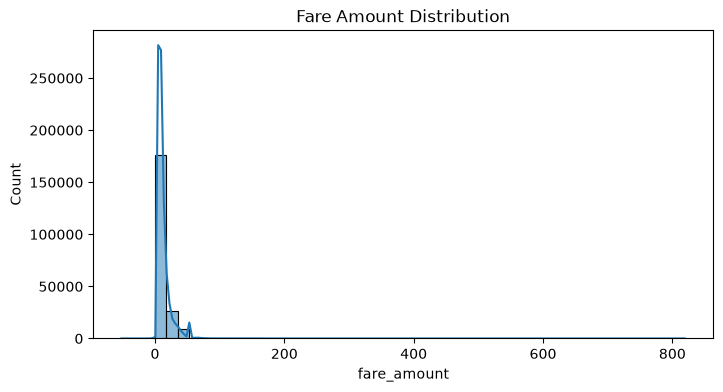

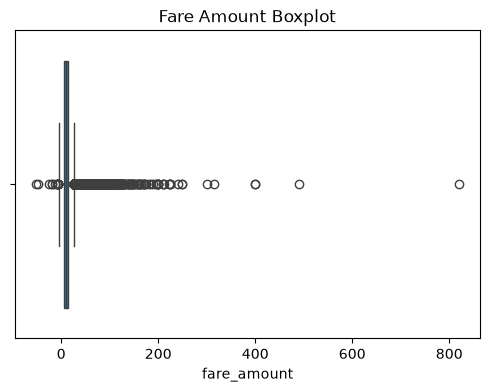

In [13]:
# 1. Univariate Analysis
#1.1 Fare Amount Distribution
#Purpose - Check if fares are skewed, contain outliers, or follow a normal pattern.

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
sns.histplot(df['fare_amount'], bins=50, kde=True)
plt.title("Fare Amount Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount Boxplot")
plt.show()


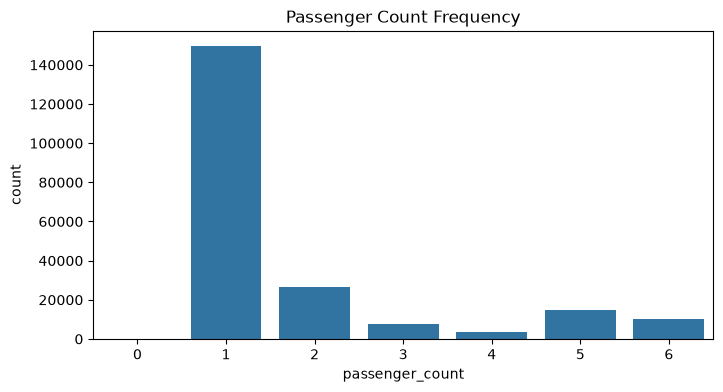

In [14]:
plt.figure(figsize=(8,4))
sns.countplot(x=df['passenger_count'])
plt.title("Passenger Count Frequency")
plt.show()


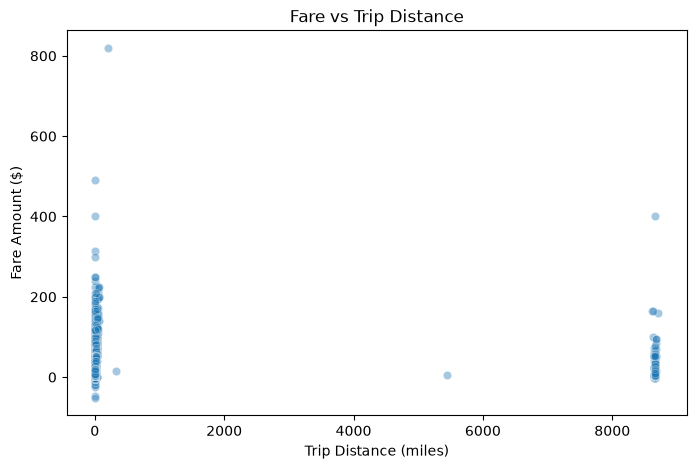

In [15]:
# 2. Bivariate Analysis
# Analyze relationships between two variables.
#2.1 Fare vs. Distance

#Purpose: See whether longer distances result in higher fares.
plt.figure(figsize=(8,5))
sns.scatterplot(x=df['trip_distance_km'], y=df['fare_amount'], alpha=0.4)
plt.title("Fare vs Trip Distance")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.show()


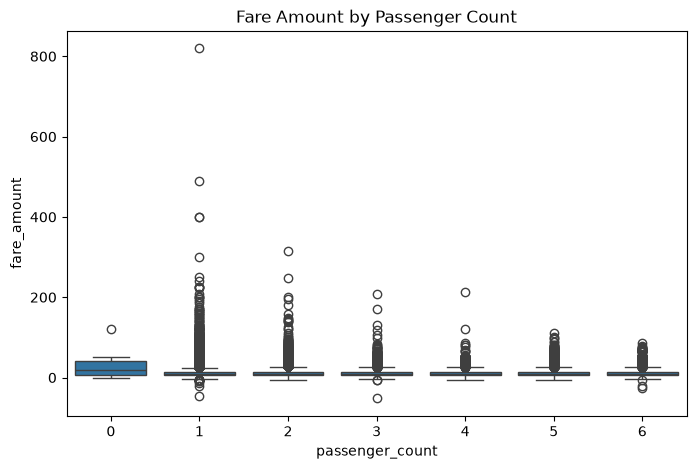

In [16]:
#2.2 Fare vs. Passenger Count

#Purpose:
#Check if having more passengers leads to higher fares.

plt.figure(figsize=(8,5))
sns.boxplot(x=df['passenger_count'], y=df['fare_amount'])
plt.title("Fare Amount by Passenger Count")
plt.show()


In [17]:
from scipy import stats

df['fare_z'] = stats.zscore(df['fare_amount'])
df['dist_z'] = stats.zscore(df['trip_distance_km'])

outliers_fare = df[df['fare_z'].abs() > 3]
outliers_dist = df[df['dist_z'].abs() > 3]

print("Fare Outliers:", len(outliers_fare))
print("Distance Outliers:", len(outliers_dist))


Fare Outliers: 5902
Distance Outliers: 539


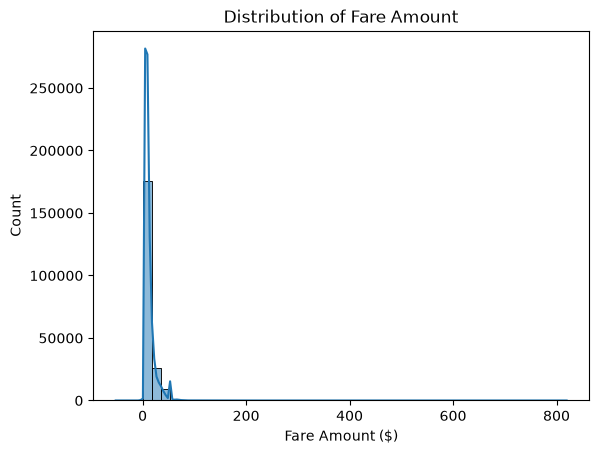

In [18]:
#Fare Distribution
#Why this is valid?

#Helps identify skewness, fare peaks, and possible outliers (e.g., unusually high/low fares).
 
sns.histplot(df['fare_amount'], bins=50, kde=True)
plt.title("Distribution of Fare Amount")
plt.xlabel("Fare Amount ($)")
plt.show()


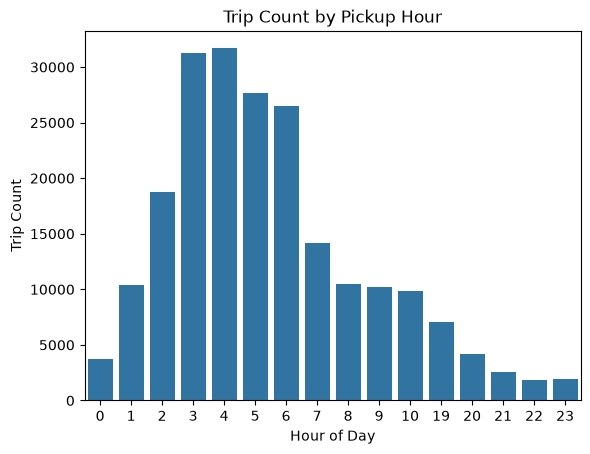

In [19]:
#Trip Count by Hour
sns.countplot(data=df, x='hour')
plt.title("Trip Count by Pickup Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Trip Count")
plt.show()


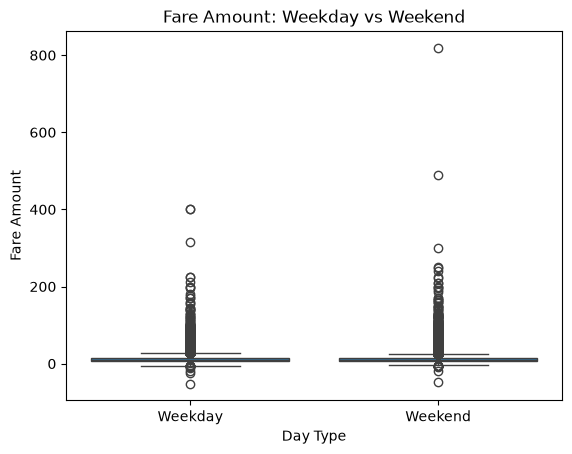

In [20]:
#Fare Amount: Weekday vs Weekend
#Column: is_weekend (0 = weekday, 1 = weekend)
sns.boxplot(data=df, x='is_weekend', y='fare_amount')
plt.title("Fare Amount: Weekday vs Weekend")
plt.xticks([0,1], ['Weekday', 'Weekend'])
plt.xlabel("Day Type")
plt.ylabel("Fare Amount")
plt.show()


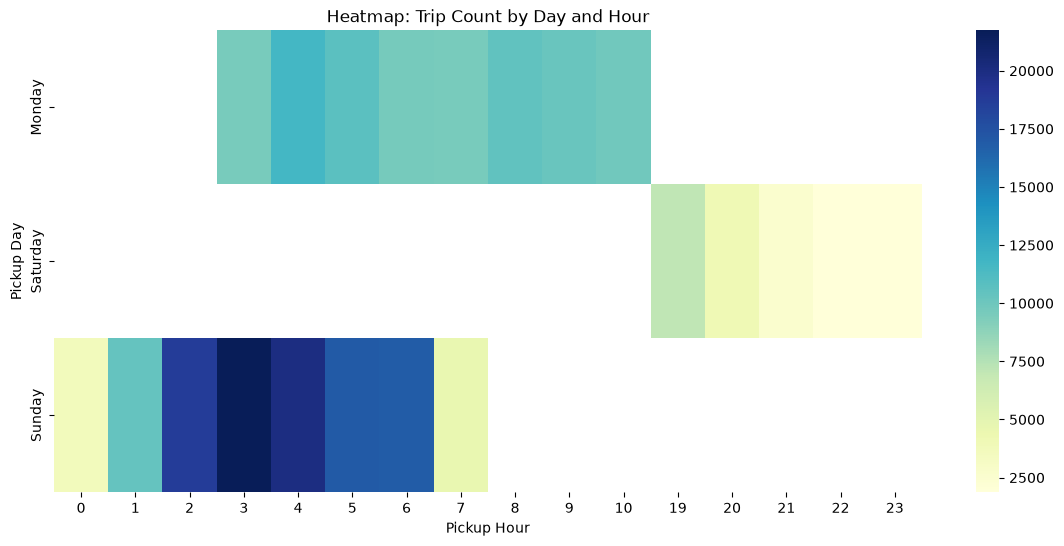

In [21]:
heat_df = df.pivot_table(
    index='pickup_day',
    columns='hour',
    values='VendorID',   # any column works, we just need trip count
    aggfunc='count'
)

plt.figure(figsize=(14,6))
sns.heatmap(heat_df, cmap='YlGnBu')
plt.title("Heatmap: Trip Count by Day and Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Pickup Day")
plt.show()

##5 Data Transformation

In [22]:
# IQR method

def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean = df[(df[column] >= lower) & (df[column] <= upper)]
    return df_clean, lower, upper


In [23]:
original_count = len(df)

df_clean, lower, upper = remove_outliers_iqr(df, 'fare_amount')

cleaned_count = len(df_clean)
removed_count = original_count - cleaned_count

print("Original rows:", original_count)
print("Rows after outlier removal:", cleaned_count)
print("Outliers removed:", removed_count)
print("Lower bound:", lower)
print("Upper bound:", upper)



Original rows: 212345
Rows after outlier removal: 194992
Outliers removed: 17353
Lower bound: -5.5
Upper bound: 26.5


In [24]:
#Label Encoding
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['pickup_day_le'] = le.fit_transform(df['pickup_day'])
df['am_pm_le'] = le.fit_transform(df['am_pm'])
df['store_and_fwd_flag_le'] = le.fit_transform(df['store_and_fwd_flag'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'], format='%d-%m-%Y %H:%M', errors='coerce')



In [25]:
df_encoded = pd.get_dummies(df, columns=['payment_type','pickup_day','am_pm'], drop_first=True)


In [26]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cat_cols = ['store_and_fwd_flag', 'pickup_day', 'am_pm']

for col in cat_cols:
    df[col] = le.fit_transform(df[col])


In [27]:
# Target column (example: fare_amount)
target = 'fare_amount'

# X = all features except target
X = df.drop(columns=[target])

# y = target variable
y = df[target]


In [28]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in X.select_dtypes(include=['object']).columns:
    X[col] = le.fit_transform(X[col])


In [29]:
# Remove datetime columns
datetime_cols = X.select_dtypes(include=['datetime64[ns]', 'datetime64[ns, UTC]']).columns
X = X.drop(columns=datetime_cols)


In [30]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(random_state=42)
model.fit(X, y)

importances = pd.Series(model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False)


fare_z                   9.831498e-01
total_amount             1.252828e-02
dropoff_latitude         9.418470e-04
extra                    4.117560e-04
VendorID                 3.485250e-04
hour                     3.203753e-04
payment_type             2.915618e-04
pickup_latitude          2.865227e-04
am_pm_le                 2.452060e-04
tolls_amount             2.249190e-04
mta_tax                  2.037935e-04
RatecodeID               1.922196e-04
dist_z                   1.850680e-04
am_pm                    1.105747e-04
is_weekend               1.088577e-04
pickup_day               1.008350e-04
pickup_longitude         8.391170e-05
improvement_surcharge    6.311587e-05
pickup_day_le            5.396122e-05
dropoff_longitude        5.075723e-05
trip_distance_km         3.264110e-05
is_night                 2.990914e-05
tip_amount               2.242584e-05
passenger_count          1.312062e-05
store_and_fwd_flag_le    4.270552e-08
store_and_fwd_flag       6.477817e-09
dtype: float

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 212345 entries, 0 to 212344
Data columns (total 29 columns):
 #   Column                 Non-Null Count   Dtype                     
---  ------                 --------------   -----                     
 0   VendorID               212345 non-null  int64                     
 1   tpep_pickup_datetime   212345 non-null  datetime64[us, US/Eastern]
 2   tpep_dropoff_datetime  212345 non-null  datetime64[us]            
 3   passenger_count        212345 non-null  int64                     
 4   pickup_longitude       212345 non-null  float64                   
 5   pickup_latitude        212345 non-null  float64                   
 6   RatecodeID             212345 non-null  int64                     
 7   store_and_fwd_flag     212345 non-null  int64                     
 8   dropoff_longitude      212345 non-null  float64                   
 9   dropoff_latitude       212345 non-null  float64                   
 10  payment_type           212345 n

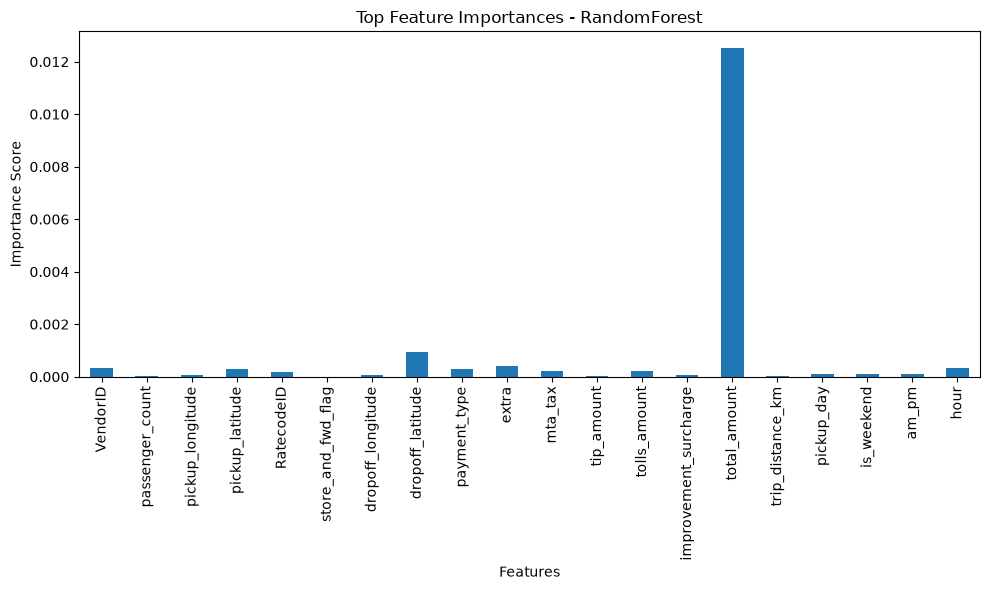

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
importances.head(20).plot(kind='bar')  # top 20 features
plt.title("Top Feature Importances - RandomForest")
plt.ylabel("Importance Score")
plt.xlabel("Features")
plt.tight_layout()
plt.show()

In [33]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [34]:
# 3. DEFINE MODELS
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

In [35]:
# 4. TRAIN & EVALUATE MODELS
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append([name, r2, mse, rmse, mae])

In [36]:
#5. RESULTS TABLE
results_df = pd.DataFrame(results, columns=["Model", "R2", "MSE", "RMSE", "MAE"])
results_df

,Model,R2,MSE,RMSE,MAE
0,Linear Regression,1.000000,0.000029,0.005406,0.000069
1,Ridge Regression,1.000000,0.000029,0.005346,0.000133
2,Lasso Regression,0.994335,0.731286,0.855153,0.486758
3,Random Forest,0.970991,3.744779,1.935143,0.010323
4,Gradient Boosting,0.979979,2.584534,1.607649,0.029466


In [37]:
df.columns

Index(['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude', 'RatecodeID',
       'store_and_fwd_flag', 'dropoff_longitude', 'dropoff_latitude',
       'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount',
       'tolls_amount', 'improvement_surcharge', 'total_amount',
       'trip_distance_km', 'pickup_day', 'is_weekend', 'am_pm', 'hour',
       'is_night', 'fare_z', 'dist_z', 'pickup_day_le', 'am_pm_le',
       'store_and_fwd_flag_le'],
      dtype='str')

In [38]:
# SELECT ONLY 4 FEATURES
features1= ['trip_distance_km', 'passenger_count', 'hour', 'pickup_day']
target1= 'fare_amount'

X = df[features1]
y = df[target1]

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
import joblib

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GradientBoostingRegressor()
model.fit(X_train, y_train)

joblib.dump(model, "best_fare_model.pkl")
print("Model saved!")


Model saved!


In [39]:
import joblib
joblib.dump(model, "best_fare_model.pkl")


['best_fare_model.pkl']